In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_fitting import gen_test_data, build_model, halofit

# gaussian

In [3]:
name = 'nfw'

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

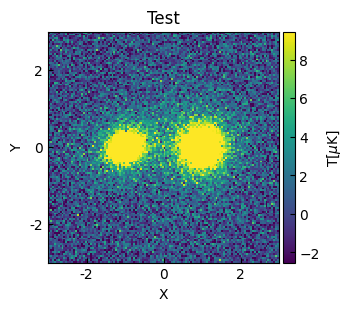

In [4]:
coord = get_coord()
kw_h1 = {
    "amplitude": 60,
    "x_mean": -1,
    "y_mean": 0,
    "r_s": 0.4,
    "ellipticity":0.2,
    "theta": 0.5
}

nstd = 2
data = gen_test_data(name, *coord, kw_h1=kw_h1, noise_std=nstd)
plot_heatmap(data, title='Test')

In [5]:
model = build_model(name, kw_h1)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=60., x_mean=-1., y_mean=0., r_s=0.4, ellipticity=0.2, theta=0.5)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... r_s_1 ellipticity_1 theta_1 amplitude_2
    ----------- -------- -------- ----- ... ----- ------------- ------- -----------
           60.0     -1.0      0.0   0.4 ...   0.5           0.0     0.0         0.0


# without mask

In [6]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=59.92501577, x_mean=-1.00002132, y_mean=0.00001338, r_s=0.39995804, ellipticity=0.19918039, theta=0.50831144)>

    [1]: <NFW2D(amplitude=50.10083328, x_mean=1.0000226, y_mean=0.00003255, r_s=0.49986761, ellipticity=0.0029974, theta=11.19918986)>

    [2]: <Const2D(amplitude=0.00484282)>
Parameters:
       amplitude_0         x_mean_0      ...      theta_1           amplitude_2     
    ----------------- ------------------ ... ------------------ --------------------
    59.92501576823226 -1.000021324374635 ... 11.199189857673215 0.004842820199483531

Goodness of fit:
Chi-squared: 57799.098
RMS residual: 2.003


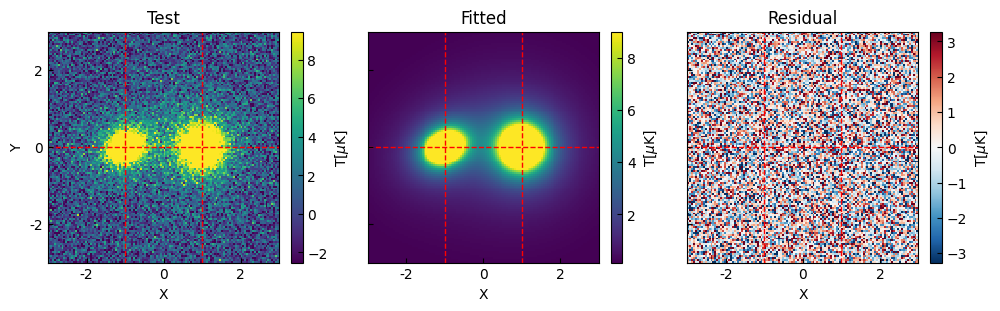

In [7]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

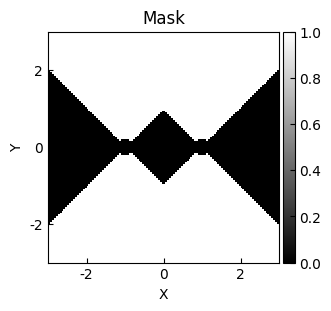

In [8]:
mask = get_mask_sector(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [9]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=60.92551042, x_mean=-0.99611205, y_mean=0.00127986, r_s=0.40160887, ellipticity=0.20459231, theta=0.43939843)>

    [1]: <NFW2D(amplitude=51.10882781, x_mean=0.99903104, y_mean=0.00004797, r_s=0.4959025, ellipticity=0.01617233, theta=-77.29982326)>

    [2]: <Const2D(amplitude=0.03024689)>
Parameters:
       amplitude_0          x_mean_0      ...     amplitude_2     
    ----------------- ------------------- ... --------------------
    60.92551041505744 -0.9961120453365203 ... 0.030246890499917994

Goodness of fit:
Chi-squared: 67549.415
RMS residual: 2.166


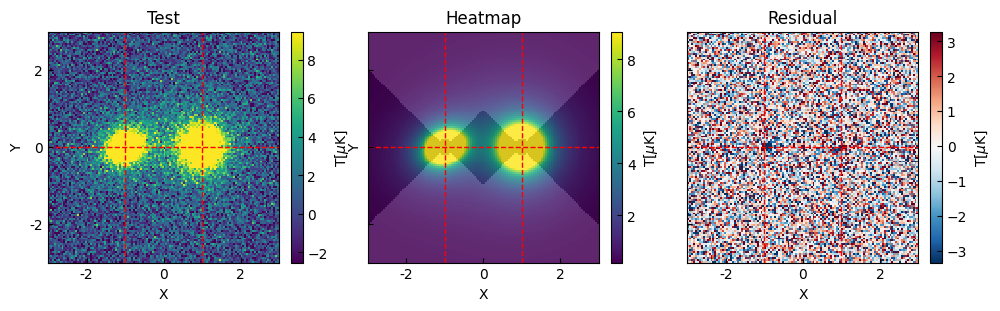

In [10]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

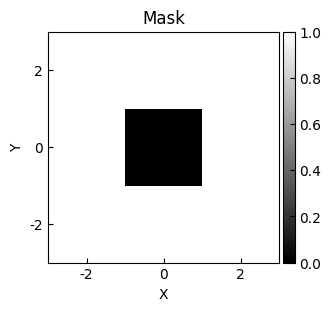

In [11]:
mask = ~get_mask_square(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [12]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <NFW2D(amplitude=60.26248318, x_mean=-0.99997177, y_mean=-0.00067965, r_s=0.39545188, ellipticity=0.18696887, theta=0.48224816)>

    [1]: <NFW2D(amplitude=51.37000102, x_mean=0.99963764, y_mean=-0.00083514, r_s=0.49644177, ellipticity=0.01964292, theta=-11.82783722)>

    [2]: <Const2D(amplitude=0.01338606)>
Parameters:
       amplitude_0          x_mean_0      ...     amplitude_2     
    ----------------- ------------------- ... --------------------
    60.26248317683482 -0.9999717674997279 ... 0.013386059701867981

Goodness of fit:
Chi-squared: 60748.926
RMS residual: 2.054


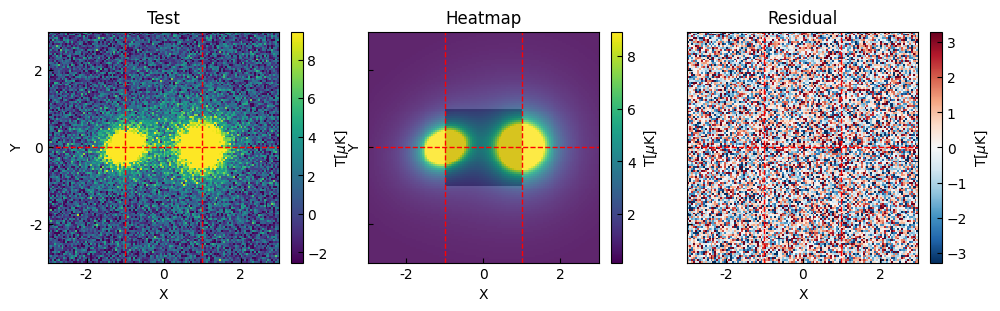

In [13]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [14]:
from mytools.plot import plot_hist

(-10.0, 10.0)

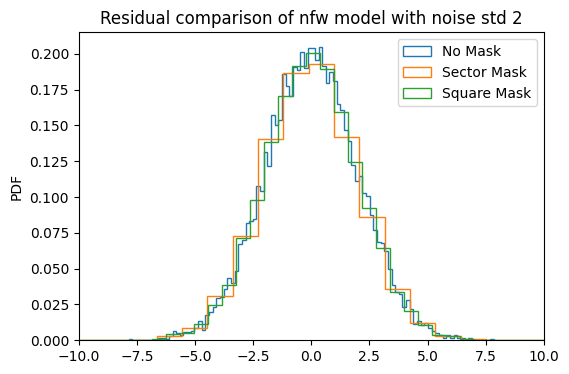

In [16]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model with noise std %d' %(name,nstd)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-10,10)